<a href="https://www.kaggle.com/code/lalit7881/airline-satisfaction-prediction-96?scriptVersionId=364133608" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


## Import libraries

In [2]:
# Import necessary libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna # Optuna for hyperparameter tuning

# Scikit-Learn tools
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, roc_curve

# Gradient Boosting Models
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

# Set plot style and suppress warnings
sns.set_theme(style="whitegrid", palette="muted")
import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING) # Keep Optuna output clean

print("Libraries imported successfully! 🚀")

Libraries imported successfully! 🚀


## Loading dataset

In [3]:
# Define paths
DATA_DIR = "/kaggle/input/competitions/playground-series-s6e10/"

In [4]:
# Load data[cite: 1]
train_df = pd.read_csv(f"{DATA_DIR}train.csv")
test_df = pd.read_csv(f"{DATA_DIR}test.csv")

In [5]:
# Separate features, target, and test IDs
TARGET = 'satisfaction'
test_ids = test_df['id']

In [6]:
X = train_df.drop(columns=['id', TARGET])
y = train_df[TARGET]
X_test = test_df.drop(columns=['id'])

In [7]:
print(f"Training data shape: {X.shape}")
print(f"Testing data shape: {X_test.shape}")
display(X.head(5))

Training data shape: (699635, 21)
Testing data shape: (299844, 21)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,36,694,4,4,4,3,1,4,1,1,...,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco
1,56,651,5,5,5,5,5,4,4,5,...,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business
2,31,1371,3,4,2,5,3,3,3,3,...,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco
3,10,1616,3,5,3,3,3,3,3,3,...,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco
4,23,481,3,4,3,4,5,3,5,5,...,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco


## EDA

In [8]:
print("🔧 Engineering new interaction features...")
for df in [X, X_test]:
    # Ratio of Flight Distance to Age (Adding 1 to avoid division by zero)
    df['Distance_per_Age'] = df['Flight Distance'] / (df['Age'] + 1)
    
    # Booking Convenience Score
    df['Booking_Convenience'] = df['Inflight wifi service'] * df['Ease of Online booking']

🔧 Engineering new interaction features...


In [9]:
# 2. Check for Missing Values
missing_train = X.isnull().sum()
missing_train = missing_train[missing_train > 0].sort_values(ascending=False)

if len(missing_train) > 0:
    print("\n⚠️ Missing values detected in training set:")
    display(pd.DataFrame({'Missing Count': missing_train, 'Percentage': (missing_train / len(X)) * 100}))
else:
    print("\n✅ No missing values found in the dataset!")


⚠️ Missing values detected in training set:


,Missing Count,Percentage
Arrival Delay in Minutes,292,0.041736


Found 19 numerical features and 4 categorical features.


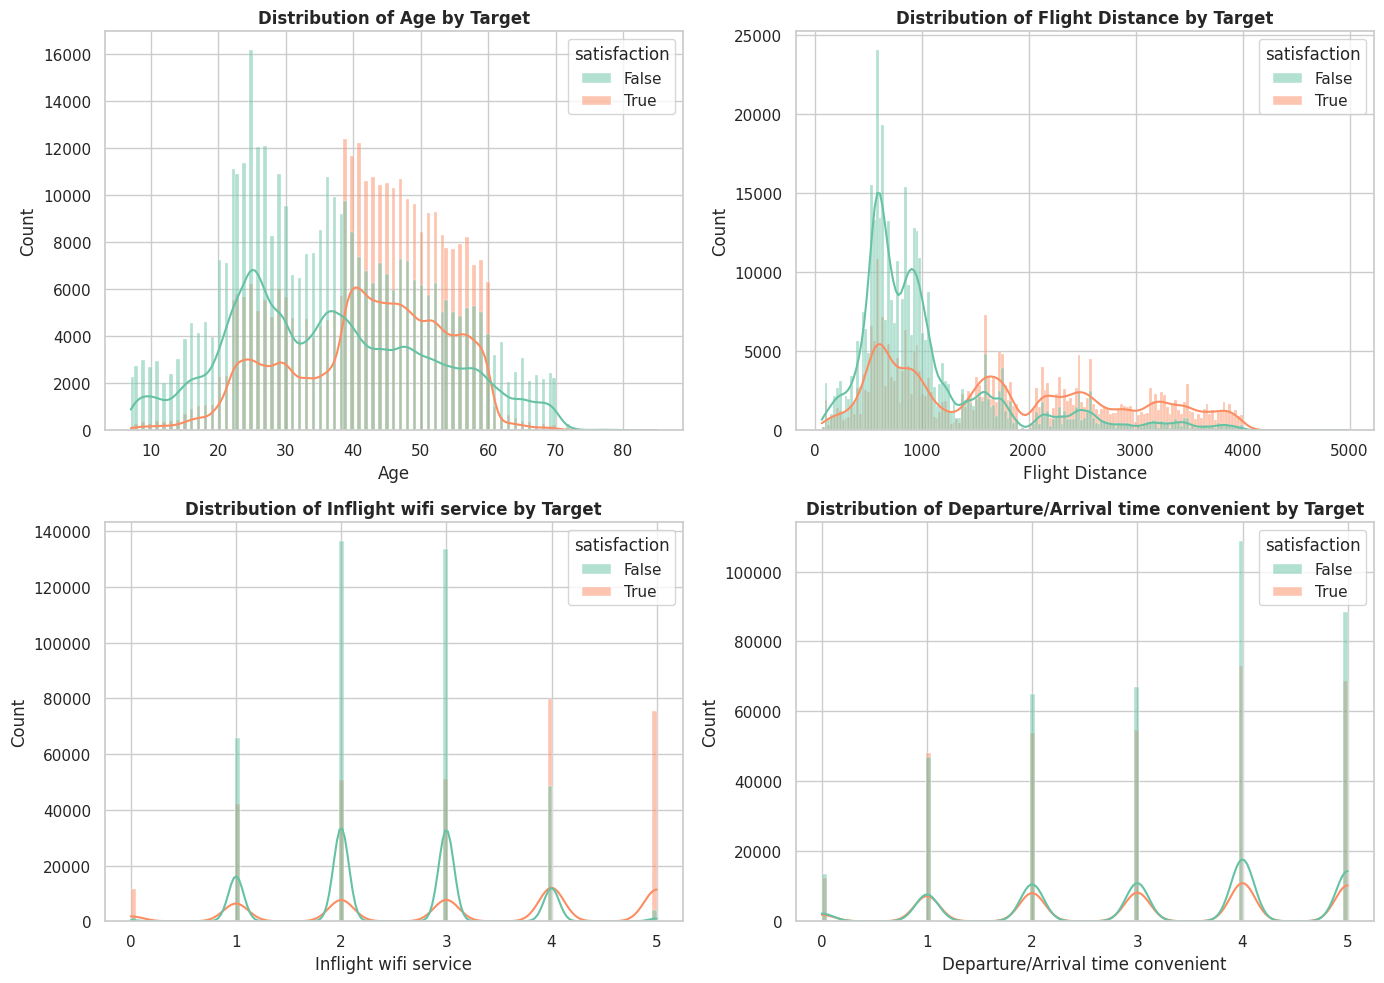

In [10]:
# Dynamically identify categorical and numerical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Found {len(num_cols)} numerical features and {len(cat_cols)} categorical features.")

# Plot distributions for the first 4 numerical features
plot_cols = num_cols[:4] if len(num_cols) >= 4 else num_cols
if plot_cols:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()
    for i, col in enumerate(plot_cols):
        sns.histplot(data=train_df, x=col, hue=TARGET, kde=True, ax=axes[i], palette='Set2')
        axes[i].set_title(f"Distribution of {col} by Target", fontweight='bold')
    plt.tight_layout()
    plt.show()

In [11]:
# 1. Numerical Pipeline
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


In [12]:
# 2. Categorical Pipeline
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])


In [13]:
# 3. Combine using ColumnTransformer[cite: 1]
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

print("✅ Preprocessing Pipeline created successfully.")

✅ Preprocessing Pipeline created successfully.


## Feature engineering

In [14]:
# Create a quick validation split solely for the Optuna objective functions
X_tune, X_val_tune, y_tune, y_val_tune = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_tune_prep = preprocessor.fit_transform(X_tune)
X_val_tune_prep = preprocessor.transform(X_val_tune)

def optimize_models(trial, model_type):
    if model_type == 'lgbm':
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 200, 600),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'max_depth': trial.suggest_int('max_depth', 4, 10),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'random_state': 42,
            'verbose': -1,
            'n_jobs': -1
        }
        model = LGBMClassifier(**params)
        
    elif model_type == 'catboost':
        params = {
            'iterations': trial.suggest_int('iterations', 200, 600),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'depth': trial.suggest_int('depth', 4, 10),
            'random_state': 42,
            'verbose': 0
        }
        model = CatBoostClassifier(**params)
        
    elif model_type == 'xgboost':
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 200, 600),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 9),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'random_state': 42,
            'eval_metric': 'auc',
            'n_jobs': -1
        }
        model = XGBClassifier(**params)
        
    model.fit(X_tune_prep, y_tune)
    preds = model.predict_proba(X_val_tune_prep)[:, 1]
    return roc_auc_score(y_val_tune, preds)

print("🔍 Tuning Models (5 trials each for demonstration)...")
# LightGBM Tuning
study_lgbm = optuna.create_study(direction='maximize')
study_lgbm.optimize(lambda t: optimize_models(t, 'lgbm'), n_trials=5)

# CatBoost Tuning
study_cat = optuna.create_study(direction='maximize')
study_cat.optimize(lambda t: optimize_models(t, 'catboost'), n_trials=5)

# XGBoost Tuning
study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(lambda t: optimize_models(t, 'xgboost'), n_trials=5)

print("\n✅ Tuning Complete!")
print(f"Best LGBM Params: {study_lgbm.best_params}")
print(f"Best CatBoost Params: {study_cat.best_params}")
print(f"Best XGBoost Params: {study_xgb.best_params}")

🔍 Tuning Models (5 trials each for demonstration)...

✅ Tuning Complete!
Best LGBM Params: {'n_estimators': 596, 'learning_rate': 0.0630524191205819, 'max_depth': 7, 'subsample': 0.6514352564229252}
Best CatBoost Params: {'iterations': 557, 'learning_rate': 0.07537864790458293, 'depth': 10}
Best XGBoost Params: {'n_estimators': 279, 'learning_rate': 0.048474213640429926, 'max_depth': 7, 'subsample': 0.6845517900276098}


In [15]:
print("🚀 Starting 5-Fold Stratified K-Fold Cross-Validation...")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Arrays to store out-of-fold and final test predictions
oof_preds = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

# Initialize optimized models
best_lgbm = LGBMClassifier(**study_lgbm.best_params, random_state=42, verbose=-1, n_jobs=-1)
best_cat = CatBoostClassifier(**study_cat.best_params, random_state=42, verbose=0)
best_xgb = XGBClassifier(**study_xgb.best_params, random_state=42, eval_metric='auc', n_jobs=-1)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    print(f"\n--- Fold {fold + 1} ---")
    
    # Split data
    X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
    y_train_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]
    
    # Preprocess Fold Data
    X_train_prep = preprocessor.fit_transform(X_train_fold)
    X_val_prep = preprocessor.transform(X_val_fold)
    X_test_prep = preprocessor.transform(X_test)
    
    # Train & Predict LightGBM
    best_lgbm.fit(X_train_prep, y_train_fold)
    lgbm_val = best_lgbm.predict_proba(X_val_prep)[:, 1]
    lgbm_test = best_lgbm.predict_proba(X_test_prep)[:, 1]
    
    # Train & Predict CatBoost
    best_cat.fit(X_train_prep, y_train_fold)
    cat_val = best_cat.predict_proba(X_val_prep)[:, 1]
    cat_test = best_cat.predict_proba(X_test_prep)[:, 1]
    
    # Train & Predict XGBoost
    best_xgb.fit(X_train_prep, y_train_fold)
    xgb_val = best_xgb.predict_proba(X_val_prep)[:, 1]
    xgb_test = best_xgb.predict_proba(X_test_prep)[:, 1]
    
    # Combine Fold Predictions (Uniform Blending)
    fold_val_preds = (lgbm_val + cat_val + xgb_val) / 3
    oof_preds[val_idx] = fold_val_preds
    
    # Accumulate Test Predictions (Averaged across 5 folds)
    test_preds += (lgbm_test + cat_test + xgb_test) / 3 / skf.n_splits
    
    fold_auc = roc_auc_score(y_val_fold, fold_val_preds)
    print(f"Fold {fold + 1} ROC AUC: {fold_auc:.5f}")

# Calculate overall OOF score
oof_auc = roc_auc_score(y, oof_preds)
print(f"\n🏆 Overall Ensembled Out-Of-Fold ROC AUC: {oof_auc:.5f}")

🚀 Starting 5-Fold Stratified K-Fold Cross-Validation...

--- Fold 1 ---
Fold 1 ROC AUC: 0.95873

--- Fold 2 ---
Fold 2 ROC AUC: 0.95766

--- Fold 3 ---
Fold 3 ROC AUC: 0.95950

--- Fold 4 ---
Fold 4 ROC AUC: 0.95884

--- Fold 5 ---
Fold 5 ROC AUC: 0.95892

🏆 Overall Ensembled Out-Of-Fold ROC AUC: 0.95872


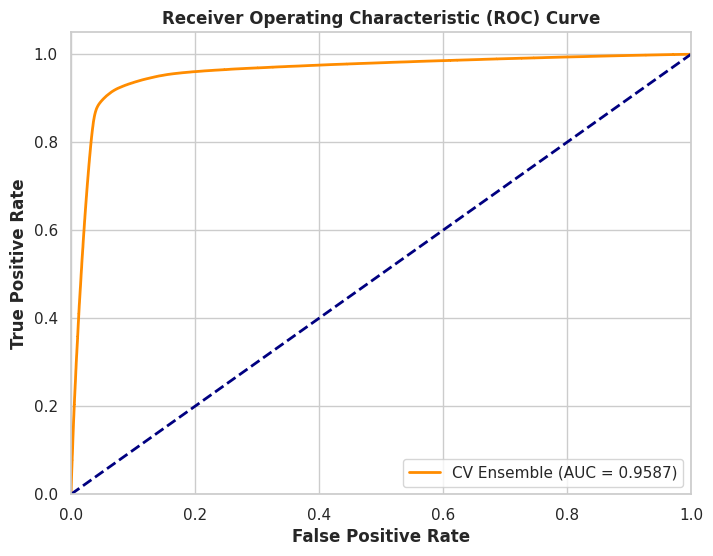

In [16]:
# Calculate False Positive Rate and True Positive Rate
fpr, tpr, thresholds = roc_curve(y, oof_preds)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'CV Ensemble (AUC = {oof_auc:.4f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title('Receiver Operating Characteristic (ROC) Curve', fontweight='bold')
plt.legend(loc="lower right")
plt.show()

In [17]:
print("🔮 Generating final submission...")

# Create submission dataframe
submission_df = pd.DataFrame({
    'id': test_ids,
    TARGET: test_preds
})

# Save to CSV
submission_df.to_csv("submission.csv", index=False)
print("✅ submission.csv created successfully!")
display(submission_df.head())

🔮 Generating final submission...
✅ submission.csv created successfully!


,id,satisfaction
0,699635,0.228126
1,699636,0.897317
2,699637,0.910161
3,699638,0.068913
4,699639,0.059740


## Thank you..pls upvote!!!!!!!